# Cookie Cats: Day-7 Retention A/B Reanalysis

A short educational analysis of an existing published experiment. We compare gate_40 with gate_30, using day-7 retention as the single primary outcome. The original experiment was not designed or conducted for this project.

Source: [Mobile Games: A/B Testing](https://www.kaggle.com/datasets/yufengsui/mobile-games-ab-testing), credited to a DataCamp project. Download the CSV into `data/raw/`; it is not redistributed here.

## 1. Load the data
Run the notebook from the project root. One row is intended to represent one player; check this before comparing outcomes.

In [1]:
import pandas as pd

from pathlib import Path

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)
df = pd.read_csv("data/raw/cookie_cats.csv")

display(df.head())
print(df.shape)

,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


(90189, 5)


## 2. Basic data checks
Check unique IDs, missingness, data types and assignment labels. These checks verify the data structure; they do not establish that the original randomization or logging was implemented correctly.

In [2]:
print("Rows and columns:", df.shape)
print("Unique players:", df["userid"].nunique())
print("Repeated ID rows:", df["userid"].duplicated().sum())

display(df.isna().sum())
display(df.dtypes)
display(df["version"].value_counts(dropna=False))

Rows and columns: (90189, 5)
Unique players: 90189
Repeated ID rows: 0


userid            0
version           0
sum_gamerounds    0
retention_1       0
retention_7       0
dtype: int64

userid            int64
version             str
sum_gamerounds    int64
retention_1        bool
retention_7        bool
dtype: object

version
gate_40    45489
gate_30    44700
Name: count, dtype: int64

## 3. Describe day-7 retention
Count all recorded players in their assigned version. Sum the Boolean return indicator and divide by group size. Keep unrounded values for calculations; rounding is only for display. No activity-based exclusions are applied.

In [3]:
summary = df.groupby("version").agg(
    players=("userid", "size"),
    returned_d7=("retention_7", "sum")
)

summary["retention_d7_pct"] = (
    summary["returned_d7"] / summary["players"] * 100
)

display(summary.round(2))

,players,returned_d7,retention_d7_pct
version,,,
gate_30,44700,8502,19.02
gate_40,45489,8279,18.20


## 4. Test equal retention rates
H0: the underlying D7 return probabilities are equal. H1: they differ in either direction. Use a two-sided two-proportion z-test with alpha = 0.05. The order is gate_40 minus gate_30.

The inference assumes independent player observations and the reported randomized assignment. A p-value is a tail probability under the null model, not the probability that H0 is true.

In [4]:
from statsmodels.stats.proportion import proportions_ztest

groups = summary.loc[["gate_40", "gate_30"]]

z_stat, p_value = proportions_ztest(
    count=groups["returned_d7"],
    nobs=groups["players"],
    alternative="two-sided"
)

print("z:", z_stat)
print("p-value:", p_value)

z: -3.164358912748191
p-value: 0.001554249975614329


## 5. Estimate the effect and uncertainty
Use a 95% Newcombe confidence interval for the difference gate_40 minus gate_30. Multiplication by 100 expresses the result in percentage points. The interval describes estimation uncertainty; it is not a 95% posterior probability statement about the fixed parameter.

In [5]:
from statsmodels.stats.proportion import confint_proportions_2indep

a = summary.loc["gate_30"]
b = summary.loc["gate_40"]

low, high = confint_proportions_2indep(
    count1=b["returned_d7"],
    nobs1=b["players"],
    count2=a["returned_d7"],
    nobs2=a["players"],
    compare="diff",
    method="newcomb",
    alpha=0.05
)

print(f"95% interval: [{low * 100:.2f}; {high * 100:.2f}] pp")

95% interval: [-1.33; -0.31] pp


## 6. Visualize the result
The point is the estimated difference. The horizontal line is the 95% confidence interval. The dashed line is zero difference.

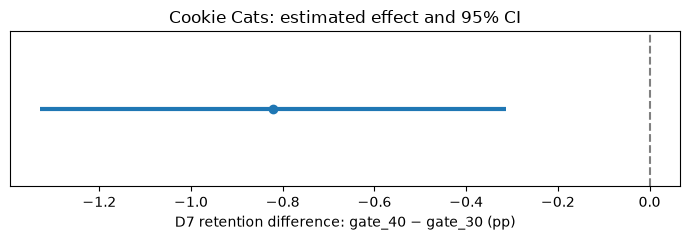

In [6]:
import matplotlib.pyplot as plt

effect = b["retention_d7_pct"] - a["retention_d7_pct"]

plt.figure(figsize=(7, 2.5))

plt.hlines(0, low * 100, high * 100, linewidth=3)
plt.plot(effect, 0, "o")
plt.axvline(0, color="gray", linestyle="--")

plt.yticks([])
plt.xlabel("D7 retention difference: gate_40 − gate_30 (pp)")
plt.title("Cookie Cats: estimated effect and 95% CI")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "cookie_cats_effect.png", dpi=150)
plt.show()

## Conclusion

Day-7 retention was **19.02% for gate_30** and **18.20% for gate_40**. The estimated difference was **-0.82 percentage points**, with a **95% confidence interval of [-1.33, -0.31] percentage points**. The two-sided test gave **p = 0.001554**.

The evidence favors retaining the gate at level 30 when D7 retention is the decision metric. Revenue is unavailable, so the analysis does not establish which version is more profitable.

This is a small reanalysis of a known educational dataset, not a new experiment or a novel discovery. The source describes random assignment, but the original allocation probabilities, full protocol and observation timestamps are unavailable. We assume complete follow-up and independent observations; a full experiment-health audit is outside this introductory scope.

## Save reproducible outputs
Export the group summary, unrounded results and environment versions.

In [7]:
import json
import platform
import importlib.metadata

summary.to_csv(OUTPUT_DIR / "summary.csv")

result = {
    "primary_metric": "retention_7",
    "comparison": "gate_40 minus gate_30",
    "alpha": 0.05,
    "alternative": "two-sided",
    "players": int(len(df)),
    "unique_players": int(df["userid"].nunique()),
    "repeated_id_rows": int(df["userid"].duplicated().sum()),
    "missing_values": {k: int(v) for k, v in df.isna().sum().items()},
    "effect_pp": float(effect),
    "z_stat": float(z_stat),
    "p_value": float(p_value),
    "ci_method": "newcomb",
    "confidence_level": 0.95,
    "ci_lower_pp": float(low * 100),
    "ci_upper_pp": float(high * 100),
    "python_version": platform.python_version(),
    "package_versions": {
        name: importlib.metadata.version(name)
        for name in ["pandas", "numpy", "scipy", "statsmodels", "matplotlib"]
    },
}

(OUTPUT_DIR / "results.json").write_text(
    json.dumps(result, indent=2) + "\n", encoding="utf-8"
)
display(result)


{'primary_metric': 'retention_7',
 'comparison': 'gate_40 minus gate_30',
 'alpha': 0.05,
 'alternative': 'two-sided',
 'players': 90189,
 'unique_players': 90189,
 'repeated_id_rows': 0,
 'missing_values': {'userid': 0,
  'version': 0,
  'sum_gamerounds': 0,
  'retention_1': 0,
  'retention_7': 0},
 'effect_pp': -0.8201298315205889,
 'z_stat': -3.164358912748191,
 'p_value': 0.001554249975614329,
 'ci_method': 'newcomb',
 'confidence_level': 0.95,
 'ci_lower_pp': -1.3281940871914846,
 'ci_upper_pp': -0.312130268876128,
 'python_version': '3.12.10',
 'package_versions': {'pandas': '3.0.6',
  'numpy': '2.5.3',
  'scipy': '1.18.1',
  'statsmodels': '0.15.0',
  'matplotlib': '3.11.2'}}